In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import jupyter
import streamlit as st
import holidays

In [2]:
# 1. Ruta relativa desde la carpeta notebooks hacia los archivos CSV
ruta_competencia = '../data/raw/entrenamiento/competencia.csv'
ruta_ventas = '../data/raw/entrenamiento/ventas.csv'

# 2. Cargar los archivos CSV en sus respectivos DataFrames
competencia_df = pd.read_csv(ruta_competencia, parse_dates=['fecha'])
ventas_df = pd.read_csv(ruta_ventas, parse_dates=['fecha'])

# 3. Mostrar las primeras filas para verificar la carga
print('Primeras filas de competencia:')
print(competencia_df.head())
print('\nPrimeras filas de ventas:')
print(ventas_df.head())

Primeras filas de competencia:
       fecha producto_id  Amazon  Decathlon  Deporvillage
0 2021-10-25    PROD_001   82.96     111.88         97.43
1 2021-10-25    PROD_002  112.56     108.61        115.58
2 2021-10-25    PROD_003   79.79      78.44         80.11
3 2021-10-25    PROD_004   72.60      67.29         74.45
4 2021-10-25    PROD_005   37.71      33.60         33.07

Primeras filas de ventas:
       fecha producto_id                            nombre categoria  \
0 2021-10-25    PROD_001          Nike Air Zoom Pegasus 40   Running   
1 2021-10-25    PROD_002              Adidas Ultraboost 23   Running   
2 2021-10-25    PROD_003               Asics Gel Nimbus 25   Running   
3 2021-10-25    PROD_004  New Balance Fresh Foam X 1080v12   Running   
4 2021-10-25    PROD_005                Nike Dri-FIT Miler   Running   

         subcategoria  precio_base  es_estrella  unidades_vendidas  \
0  Zapatillas Running          115         True                  6   
1  Zapatillas Running

In [3]:
# 4. Revisar la estructura, los tipos y los valores nulos
print('Dimensiones:', ventas_df.shape)
print('\nTipos de datos por variable:')
print(ventas_df.dtypes)
print('\nValores nulos por variable:')
print(ventas_df.isna().sum())

# 5. Revisar registros duplicados y la unicidad fecha-producto
print('\nFilas completamente duplicadas:', ventas_df.duplicated().sum())
print('Claves fecha-producto duplicadas:', ventas_df.duplicated(subset=['fecha', 'producto_id']).sum())

# 6. Validar fechas, cobertura por fecha y consistencia de ingresos
fechas_validas = pd.to_datetime(ventas_df['fecha'], errors='coerce')
productos_esperados = ventas_df['producto_id'].nunique()
productos_por_fecha = ventas_df.groupby('fecha')['producto_id'].nunique()
ingresos_calculados = ventas_df['unidades_vendidas'] * ventas_df['precio_venta']
inconsistencias_ingresos = (ventas_df['ingresos'] - ingresos_calculados).abs() > 0.01
print('\nFechas no convertibles:', fechas_validas.isna().sum())
print('Rango de fechas:', fechas_validas.min(), 'a', fechas_validas.max())
print('Fechas sin todos los productos:', (productos_por_fecha != productos_esperados).sum())
print('Ingresos distintos de unidades x precio de venta:', inconsistencias_ingresos.sum())
ventas_sobre_precio_base = ventas_df['precio_venta'] > ventas_df['precio_base']
print('Precios de venta superiores al precio base:', ventas_sobre_precio_base.sum())

# 7. Validar valores numéricos no positivos
print('\nValores no positivos por variable:')
print((ventas_df[['precio_base', 'unidades_vendidas', 'precio_venta', 'ingresos']] <= 0).sum())

# 8. Revisar descriptivos numéricos y categóricos
print('\nEstadísticos descriptivos:')
print(ventas_df.describe(include='all').T.to_string())

# 9. Contar posibles valores atípicos con el criterio IQR (para revisión, no implica error)
for variable in ['precio_base', 'unidades_vendidas', 'precio_venta', 'ingresos']:
    cuartil_1 = ventas_df[variable].quantile(0.25)
    cuartil_3 = ventas_df[variable].quantile(0.75)
    rango_iqr = cuartil_3 - cuartil_1
    limite_inferior = cuartil_1 - 1.5 * rango_iqr
    limite_superior = cuartil_3 + 1.5 * rango_iqr
    valores_atipicos = ((ventas_df[variable] < limite_inferior) | (ventas_df[variable] > limite_superior)).sum()
    print(f'{variable}: {valores_atipicos} posibles valores atípicos')

# 10. Emitir el dictamen general de calidad
hay_nulos = ventas_df.isna().any().any()
hay_duplicados = ventas_df.duplicated().any() or ventas_df.duplicated(subset=['fecha', 'producto_id']).any()
hay_fechas_invalidas = fechas_validas.isna().any()
hay_ingresos_inconsistentes = inconsistencias_ingresos.any()
hay_no_positivos = (ventas_df[['precio_base', 'unidades_vendidas', 'precio_venta', 'ingresos']] <= 0).any().any()
if hay_nulos or hay_duplicados or hay_fechas_invalidas or hay_ingresos_inconsistentes or hay_no_positivos:
    print('\nDictamen: se detectaron incidencias que requieren revisión.')
else:
    print('\nDictamen: sin incidencias estructurales en nulos, duplicados, fechas, valores positivos ni cálculo de ingresos.')
print('Nota: fecha se carga como datetime y está lista para el análisis temporal.')
print('Nota: los valores atípicos IQR y precios de venta superiores al precio base requieren contexto de negocio; no son errores automáticamente.')

Dimensiones: (3552, 10)

Tipos de datos por variable:
fecha                datetime64[us]
producto_id                     str
nombre                          str
categoria                       str
subcategoria                    str
precio_base                   int64
es_estrella                    bool
unidades_vendidas             int64
precio_venta                float64
ingresos                    float64
dtype: object

Valores nulos por variable:
fecha                0
producto_id          0
nombre               0
categoria            0
subcategoria         0
precio_base          0
es_estrella          0
unidades_vendidas    0
precio_venta         0
ingresos             0
dtype: int64

Filas completamente duplicadas: 0
Claves fecha-producto duplicadas: 0

Fechas no convertibles: 0
Rango de fechas: 2021-10-25 00:00:00 a 2024-11-30 00:00:00
Fechas sin todos los productos: 0
Ingresos distintos de unidades x precio de venta: 0
Precios de venta superiores al precio base: 1567

Valores

In [4]:
# 11. Revisar la estructura, los tipos y los valores nulos de competencia_df
print('Dimensiones:', competencia_df.shape)
print('\nTipos de datos por variable:')
print(competencia_df.dtypes)
print('\nValores nulos por variable:')
print(competencia_df.isna().sum())

# 12. Revisar duplicados y unicidad de la clave fecha-producto
print('\nFilas completamente duplicadas:', competencia_df.duplicated().sum())
print('Claves fecha-producto duplicadas:', competencia_df.duplicated(subset=['fecha', 'producto_id']).sum())

# 13. Validar fechas, cobertura de productos y correspondencia con ventas_df
fechas_competencia_validas = pd.to_datetime(competencia_df['fecha'], errors='coerce')
productos_competencia_esperados = competencia_df['producto_id'].nunique()
productos_competencia_por_fecha = competencia_df.groupby('fecha')['producto_id'].nunique()
claves_competencia = set(zip(competencia_df['fecha'], competencia_df['producto_id']))
claves_ventas = set(zip(ventas_df['fecha'], ventas_df['producto_id']))
print('\nFechas no convertibles:', fechas_competencia_validas.isna().sum())
print('Rango de fechas:', fechas_competencia_validas.min(), 'a', fechas_competencia_validas.max())
print('Fechas sin todos los productos:', (productos_competencia_por_fecha != productos_competencia_esperados).sum())
print('Claves de competencia sin correspondencia en ventas_df:', len(claves_competencia - claves_ventas))
print('Claves de ventas_df sin correspondencia en competencia_df:', len(claves_ventas - claves_competencia))

# 14. Revisar descriptivos y precios no positivos de cada competidor
columnas_precios = ['Amazon', 'Decathlon', 'Deporvillage']
print('\nEstadísticos descriptivos:')
print(competencia_df.describe(include='all').T.to_string())
print('\nPrecios no positivos por competidor:')
print((competencia_df[columnas_precios] <= 0).sum())

# 15. Contar posibles valores atípicos IQR por competidor
for competidor in columnas_precios:
    cuartil_1 = competencia_df[competidor].quantile(0.25)
    cuartil_3 = competencia_df[competidor].quantile(0.75)
    rango_iqr = cuartil_3 - cuartil_1
    limite_inferior = cuartil_1 - 1.5 * rango_iqr
    limite_superior = cuartil_3 + 1.5 * rango_iqr
    valores_atipicos = ((competencia_df[competidor] < limite_inferior) | (competencia_df[competidor] > limite_superior)).sum()
    print(f'{competidor}: {valores_atipicos} posibles valores atípicos IQR')

# 16. Emitir el dictamen general de calidad
hay_nulos_competencia = competencia_df.isna().any().any()
hay_duplicados_competencia = competencia_df.duplicated().any() or competencia_df.duplicated(subset=['fecha', 'producto_id']).any()
hay_fechas_competencia_invalidas = fechas_competencia_validas.isna().any()
hay_precios_competencia_no_positivos = (competencia_df[columnas_precios] <= 0).any().any()
hay_claves_sin_correspondencia = claves_competencia != claves_ventas
if hay_nulos_competencia or hay_duplicados_competencia or hay_fechas_competencia_invalidas or hay_precios_competencia_no_positivos or hay_claves_sin_correspondencia:
    print('\nDictamen: se detectaron incidencias estructurales que requieren revisión.')
else:
    print('\nDictamen: sin incidencias estructurales en nulos, duplicados, fechas, precios positivos ni correspondencia con ventas_df.')
print('Nota: fecha se carga como datetime y está lista para el análisis temporal.')
print('Nota: los valores atípicos IQR deben revisarse por producto; el análisis global mezcla productos con distintos niveles de precio.')

Dimensiones: (3552, 5)

Tipos de datos por variable:
fecha           datetime64[us]
producto_id                str
Amazon                 float64
Decathlon              float64
Deporvillage           float64
dtype: object

Valores nulos por variable:
fecha           0
producto_id     0
Amazon          0
Decathlon       0
Deporvillage    0
dtype: int64

Filas completamente duplicadas: 0
Claves fecha-producto duplicadas: 0

Fechas no convertibles: 0
Rango de fechas: 2021-10-25 00:00:00 a 2024-11-30 00:00:00
Fechas sin todos los productos: 0
Claves de competencia sin correspondencia en ventas_df: 0
Claves de ventas_df sin correspondencia en competencia_df: 0

Estadísticos descriptivos:
               count unique       top freq                 mean                  min                  25%                  50%                  75%                  max         std
fecha           3552    NaN       NaN  NaN  2023-05-13 18:00:00  2021-10-25 00:00:00  2022-08-03 18:00:00  2023-05-13 12:00:00 

In [5]:
ventas_df.info

<bound method DataFrame.info of           fecha producto_id                            nombre categoria  \
0    2021-10-25    PROD_001          Nike Air Zoom Pegasus 40   Running   
1    2021-10-25    PROD_002              Adidas Ultraboost 23   Running   
2    2021-10-25    PROD_003               Asics Gel Nimbus 25   Running   
3    2021-10-25    PROD_004  New Balance Fresh Foam X 1080v12   Running   
4    2021-10-25    PROD_005                Nike Dri-FIT Miler   Running   
...         ...         ...                               ...       ...   
3547 2024-11-30    PROD_020                     Quechua MH500   Outdoor   
3548 2024-11-30    PROD_021              Manduka PRO Yoga Mat  Wellness   
3549 2024-11-30    PROD_022          Gaiam Premium Yoga Block  Wellness   
3550 2024-11-30    PROD_023                  Liforme Yoga Pad  Wellness   
3551 2024-11-30    PROD_024          Lotuscrafts Yoga Bolster  Wellness   

            subcategoria  precio_base  es_estrella  unidades_vendid

In [6]:
competencia_df.info

<bound method DataFrame.info of           fecha producto_id    Amazon  Decathlon  Deporvillage
0    2021-10-25    PROD_001   82.9600     111.88       97.4300
1    2021-10-25    PROD_002  112.5600     108.61      115.5800
2    2021-10-25    PROD_003   79.7900      78.44       80.1100
3    2021-10-25    PROD_004   72.6000      67.29       74.4500
4    2021-10-25    PROD_005   37.7100      33.60       33.0700
...         ...         ...       ...        ...           ...
3547 2024-11-30    PROD_020   86.2000      72.75       82.6800
3548 2024-11-30    PROD_021  141.7125     120.60      132.1875
3549 2024-11-30    PROD_022   20.3700      17.62       20.2900
3550 2024-11-30    PROD_023   32.6400      34.06       33.2300
3551 2024-11-30    PROD_024   46.5800      45.58       50.0800

[3552 rows x 5 columns]>

In [7]:
# 17. Integrar ventas y precios de la competencia usando fecha y producto_id como claves
df = pd.merge(
    ventas_df,
    competencia_df,
    on=['fecha', 'producto_id'],
    how='inner',
    validate='one_to_one'
)
# Verificar las dimensiones y las primeras filas del DataFrame integrado
print('Dimensiones de df:', df.shape)
print(df.head())

Dimensiones de df: (3552, 13)
       fecha producto_id                            nombre categoria  \
0 2021-10-25    PROD_001          Nike Air Zoom Pegasus 40   Running   
1 2021-10-25    PROD_002              Adidas Ultraboost 23   Running   
2 2021-10-25    PROD_003               Asics Gel Nimbus 25   Running   
3 2021-10-25    PROD_004  New Balance Fresh Foam X 1080v12   Running   
4 2021-10-25    PROD_005                Nike Dri-FIT Miler   Running   

         subcategoria  precio_base  es_estrella  unidades_vendidas  \
0  Zapatillas Running          115         True                  6   
1  Zapatillas Running          135         True                 10   
2  Zapatillas Running           85        False                  2   
3  Zapatillas Running           75        False                  2   
4        Ropa Running           35        False                  2   

   precio_venta  ingresos  Amazon  Decathlon  Deporvillage  
0        118.36    710.16   82.96     111.88         97

In [8]:
df.head

<bound method NDFrame.head of           fecha producto_id                            nombre categoria  \
0    2021-10-25    PROD_001          Nike Air Zoom Pegasus 40   Running   
1    2021-10-25    PROD_002              Adidas Ultraboost 23   Running   
2    2021-10-25    PROD_003               Asics Gel Nimbus 25   Running   
3    2021-10-25    PROD_004  New Balance Fresh Foam X 1080v12   Running   
4    2021-10-25    PROD_005                Nike Dri-FIT Miler   Running   
...         ...         ...                               ...       ...   
3547 2024-11-30    PROD_020                     Quechua MH500   Outdoor   
3548 2024-11-30    PROD_021              Manduka PRO Yoga Mat  Wellness   
3549 2024-11-30    PROD_022          Gaiam Premium Yoga Block  Wellness   
3550 2024-11-30    PROD_023                  Liforme Yoga Pad  Wellness   
3551 2024-11-30    PROD_024          Lotuscrafts Yoga Bolster  Wellness   

            subcategoria  precio_base  es_estrella  unidades_vendidas

## Analisis exploratorio de ventas

Resumen de calidad y distribucion de `df`, seguido de visualizaciones temporales y categoricas.

In [9]:
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.0)

print(f'Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas')
print(f'Rango de fechas: {df["fecha"].min():%Y-%m-%d} a {df["fecha"].max():%Y-%m-%d}')
print(f'Filas duplicadas: {df.duplicated().sum()}')
print(f'Claves fecha-producto duplicadas: {df.duplicated(subset=["fecha", "producto_id"]).sum()}')

print('\nTipos de datos:')
display(df.dtypes.to_frame(name='tipo'))

print('\nValores nulos por columna:')
display(df.isna().sum().to_frame(name='valores_nulos'))

print('\nResumen estadistico:')
display(df.describe(include='all').T)

print('\nRegistros por ano:')
display(df.assign(ano=pd.to_datetime(df['fecha']).dt.year)
        .groupby('ano', as_index=False)
        .agg(registros=('producto_id', 'size'), fecha_inicio=('fecha', 'min'),
             fecha_fin=('fecha', 'max'), unidades_vendidas=('unidades_vendidas', 'sum')))

Dimensiones: 3552 filas x 13 columnas
Rango de fechas: 2021-10-25 a 2024-11-30
Filas duplicadas: 0
Claves fecha-producto duplicadas: 0

Tipos de datos:


,tipo
fecha,datetime64[us]
producto_id,str
nombre,str
categoria,str
subcategoria,str
precio_base,int64
es_estrella,bool
unidades_vendidas,int64
precio_venta,float64
ingresos,float64



Valores nulos por columna:


,valores_nulos
fecha,0
producto_id,0
nombre,0
categoria,0
subcategoria,0
precio_base,0
es_estrella,0
unidades_vendidas,0
precio_venta,0
ingresos,0



Resumen estadistico:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
fecha,3552,NaN,NaN,NaN,2023-05-13 18:00:00,2021-10-25 00:00:00,2022-08-03 18:00:00,2023-05-13 12:00:00,2024-02-20 12:00:00,2024-11-30 00:00:00,NaN
producto_id,3552,24,PROD_001,148,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nombre,3552,24,Nike Air Zoom Pegasus 40,148,NaN,NaN,NaN,NaN,NaN,NaN,NaN
categoria,3552,4,Running,1184,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subcategoria,3552,16,Zapatillas Running,888,NaN,NaN,NaN,NaN,NaN,NaN,NaN
precio_base,3552.0,NaN,NaN,NaN,123.125,20.0,48.75,72.5,118.75,830.0,165.576753
es_estrella,3552,2,False,2516,NaN,NaN,NaN,NaN,NaN,NaN,NaN
unidades_vendidas,3552.0,NaN,NaN,NaN,4.87866,1.0,2.0,3.0,5.0,85.0,6.31102
precio_venta,3552.0,NaN,NaN,NaN,121.816546,19.0,47.2125,71.81,118.22,854.22,164.017963
ingresos,3552.0,NaN,NaN,NaN,605.972323,19.46,131.535,216.57,639.6375,14508.4,1079.071192



Registros por ano:


,ano,registros,fecha_inicio,fecha_fin,unidades_vendidas
0,2021,888,2021-10-25,2021-11-30,3766
1,2022,888,2022-10-25,2022-11-30,4325
2,2023,888,2023-10-25,2023-11-30,4805
3,2024,888,2024-10-25,2024-11-30,4433


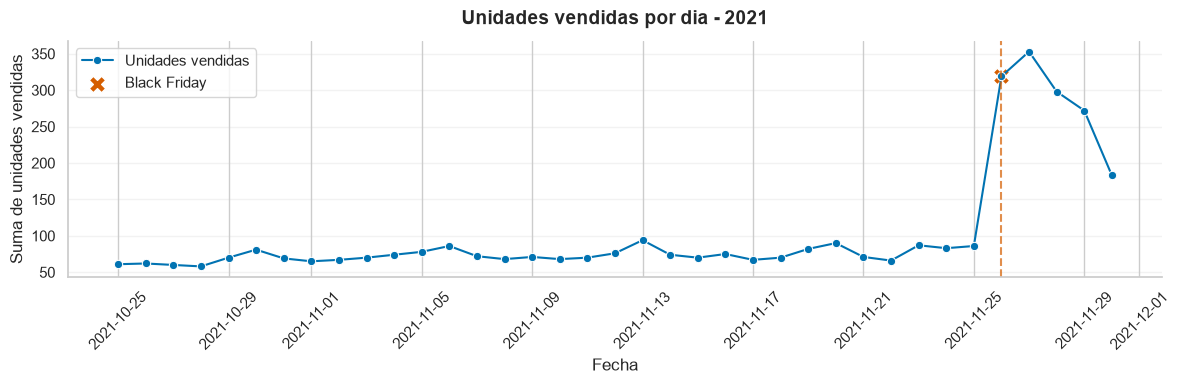

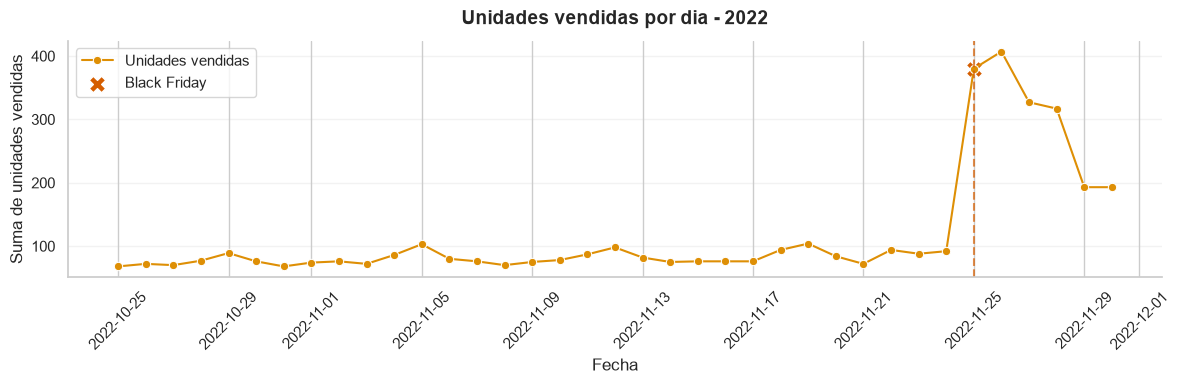

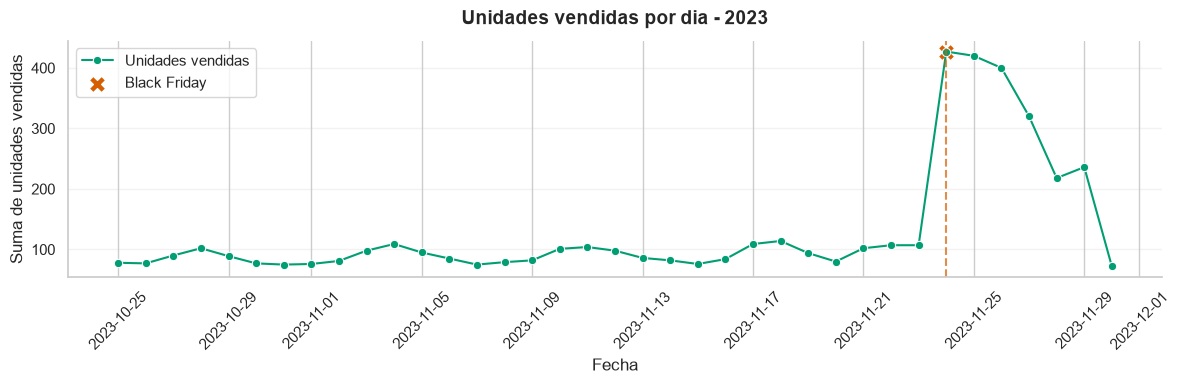

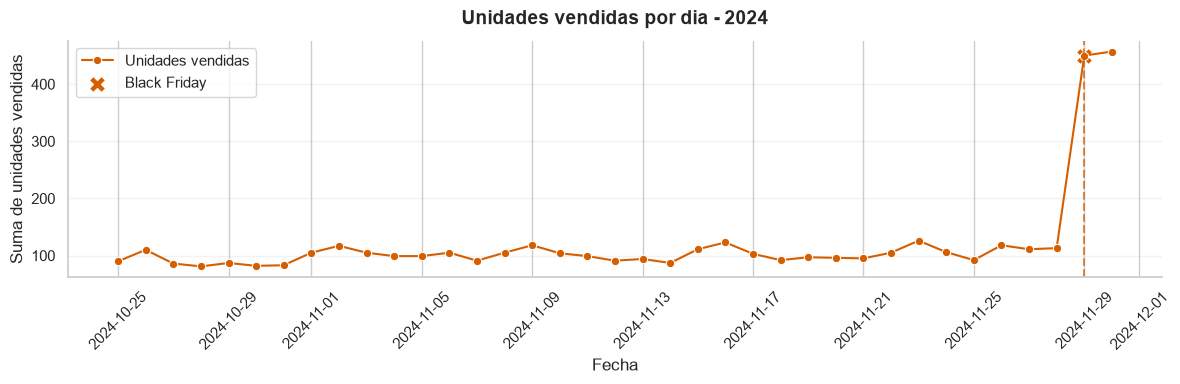

In [10]:
ventas_diarias = (df.assign(fecha=pd.to_datetime(df['fecha']))
                  .groupby('fecha', as_index=False)['unidades_vendidas'].sum())
anos = sorted(ventas_diarias['fecha'].dt.year.unique())

# Black Friday es el viernes siguiente al Thanksgiving de Estados Unidos.
calendario_us = holidays.country_holidays('US', years=anos)
black_fridays = {
    dia.year: pd.Timestamp(dia) + pd.Timedelta(days=1)
    for dia, nombre in calendario_us.items()
    if 'Thanksgiving' in nombre
}

colores_ano = sns.color_palette('colorblind', n_colors=len(anos))
for indice, ano in enumerate(anos):
    ventas_ano = ventas_diarias[ventas_diarias['fecha'].dt.year == ano]
    fig, ax = plt.subplots(figsize=(12, 4))
    sns.lineplot(data=ventas_ano, x='fecha', y='unidades_vendidas', marker='o',
                 color=colores_ano[indice], label='Unidades vendidas', ax=ax)

    fecha_black_friday = black_fridays.get(ano)
    if fecha_black_friday is not None:
        ventas_black_friday = ventas_ano[ventas_ano['fecha'] == fecha_black_friday]
        if not ventas_black_friday.empty:
            ax.axvline(fecha_black_friday, color='#D55E00', linestyle='--', alpha=0.7)
            sns.scatterplot(data=ventas_black_friday, x='fecha', y='unidades_vendidas',
                            marker='X', s=140, color='#D55E00', label='Black Friday', ax=ax)

    ax.set_title(f'Unidades vendidas por dia - {ano}', fontsize=14, fontweight='bold', pad=12)
    ax.set(xlabel='Fecha',
           ylabel='Suma de unidades vendidas')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', alpha=0.25)
    ax.legend()
    sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()

C:\Users\Vehiller\AppData\Local\Temp\ipykernel_12696\3242144245.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  pd.to_datetime(df['fecha']).dt.dayofweek.map(dict(enumerate(dias_semana))),


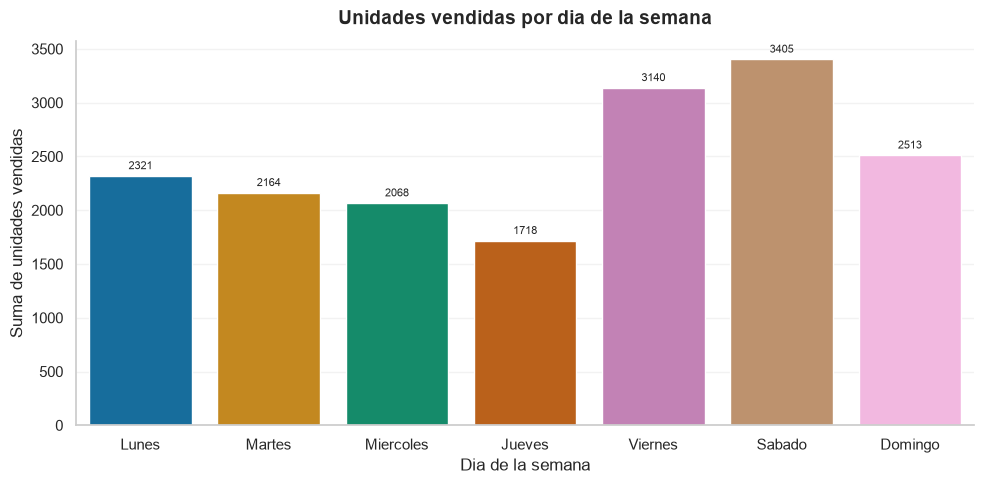

In [11]:
dias_semana = ['Lunes', 'Martes', 'Miercoles', 'Jueves', 'Viernes', 'Sabado', 'Domingo']
ventas_por_dia = (df.assign(
    dia_semana=pd.Categorical(
        pd.to_datetime(df['fecha']).dt.dayofweek.map(dict(enumerate(dias_semana))),
        categories=dias_semana,
        ordered=True,
    )
)
    .groupby('dia_semana', observed=False)['unidades_vendidas'].sum()
    .reindex(dias_semana)
    .reset_index(name='unidades_vendidas'))

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=ventas_por_dia, x='dia_semana', y='unidades_vendidas',
            hue='dia_semana', hue_order=dias_semana,
            palette=sns.color_palette('colorblind', n_colors=len(dias_semana)),
            dodge=False, legend=False, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=8)
ax.set_title('Unidades vendidas por dia de la semana', fontsize=14, fontweight='bold', pad=12)
ax.set(xlabel='Dia de la semana',
       ylabel='Suma de unidades vendidas')
ax.grid(axis='y', alpha=0.25)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

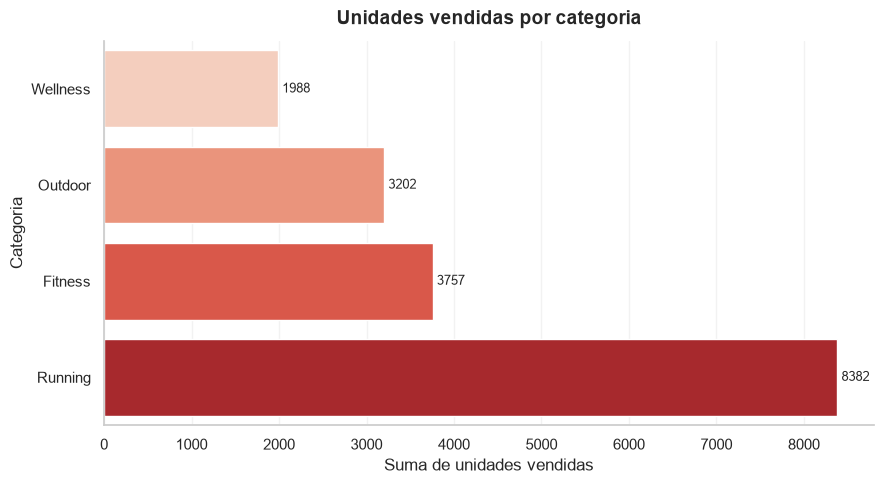

In [12]:
ventas_por_categoria = (df.groupby('categoria', as_index=False)['unidades_vendidas']
                        .sum().sort_values('unidades_vendidas'))

orden_categorias = ventas_por_categoria['categoria'].tolist()
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=ventas_por_categoria, x='unidades_vendidas', y='categoria',
            hue='categoria', hue_order=orden_categorias,
            palette=sns.color_palette('Reds', n_colors=len(orden_categorias)),
            dodge=False, legend=False, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=9)
ax.set_title('Unidades vendidas por categoria', fontsize=14, fontweight='bold', pad=12)
ax.set(xlabel='Suma de unidades vendidas', ylabel='Categoria')
ax.grid(axis='x', alpha=0.25)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

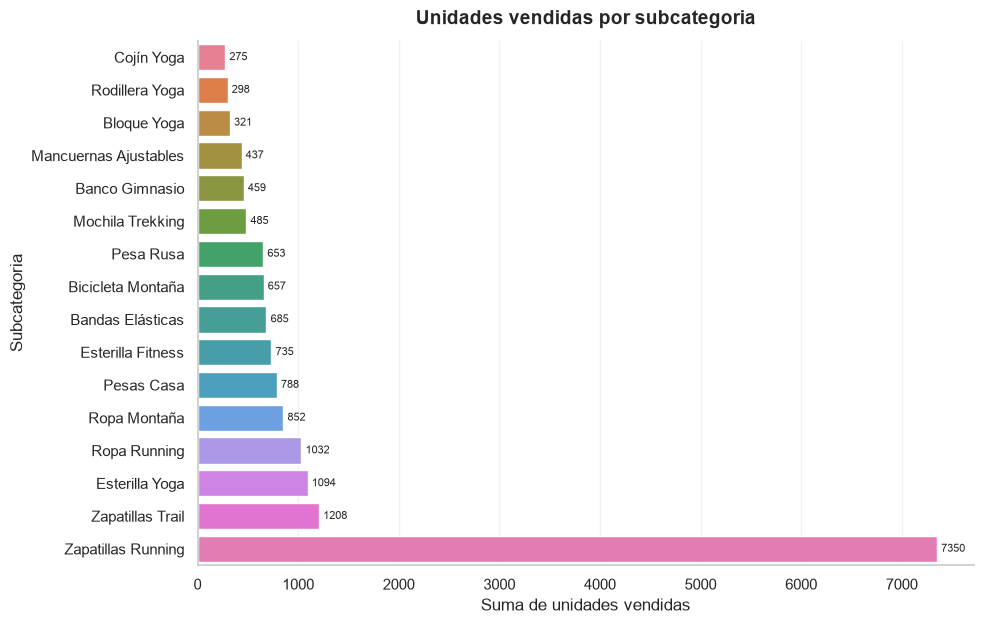

In [13]:
ventas_por_subcategoria = (df.groupby('subcategoria', as_index=False)['unidades_vendidas']
                           .sum().sort_values('unidades_vendidas'))

orden_subcategorias = ventas_por_subcategoria['subcategoria'].tolist()
fig, ax = plt.subplots(figsize=(10, max(5, 0.4 * len(ventas_por_subcategoria))))
sns.barplot(data=ventas_por_subcategoria, x='unidades_vendidas', y='subcategoria',
            hue='subcategoria', hue_order=orden_subcategorias,
            palette=sns.color_palette('husl', n_colors=len(orden_subcategorias)),
            dodge=False, legend=False, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=8)
ax.set_title('Unidades vendidas por subcategoria', fontsize=14, fontweight='bold', pad=12)
ax.set(xlabel='Suma de unidades vendidas', ylabel='Subcategoria')
ax.grid(axis='x', alpha=0.25)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

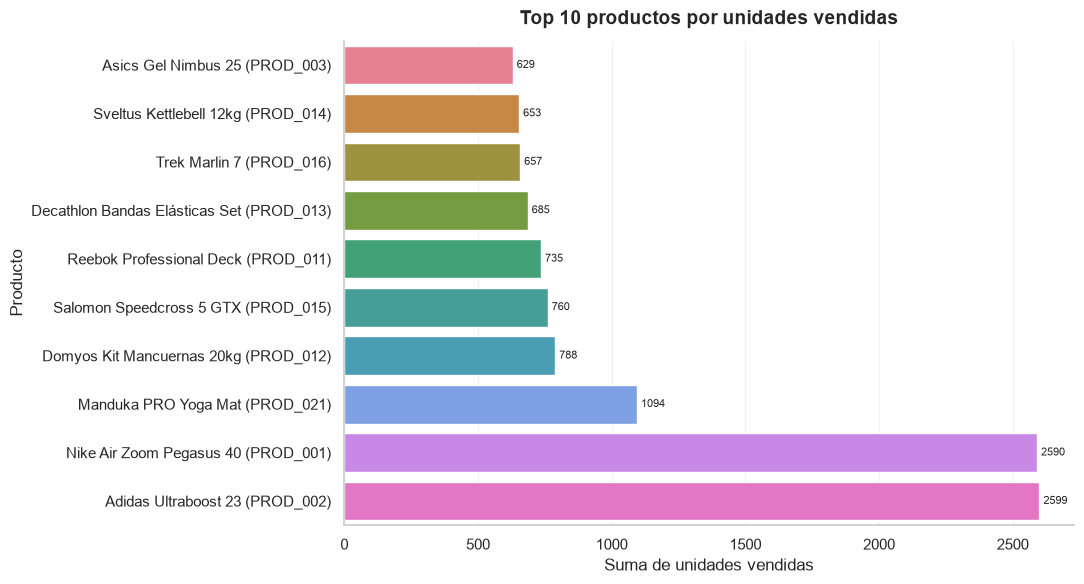

In [14]:
top_productos = (df.groupby(['producto_id', 'nombre'], as_index=False)['unidades_vendidas']
                 .sum().nlargest(10, 'unidades_vendidas')
                 .sort_values('unidades_vendidas'))
top_productos['producto'] = top_productos['nombre'] + ' (' + top_productos['producto_id'] + ')'

orden_productos = top_productos['producto'].tolist()
fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=top_productos, x='unidades_vendidas', y='producto',
            hue='producto', hue_order=orden_productos,
            palette=sns.color_palette('husl', n_colors=len(orden_productos)),
            dodge=False, legend=False, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=8)
ax.set_title('Top 10 productos por unidades vendidas', fontsize=14, fontweight='bold', pad=12)
ax.set(xlabel='Suma de unidades vendidas', ylabel='Producto')
ax.grid(axis='x', alpha=0.25)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

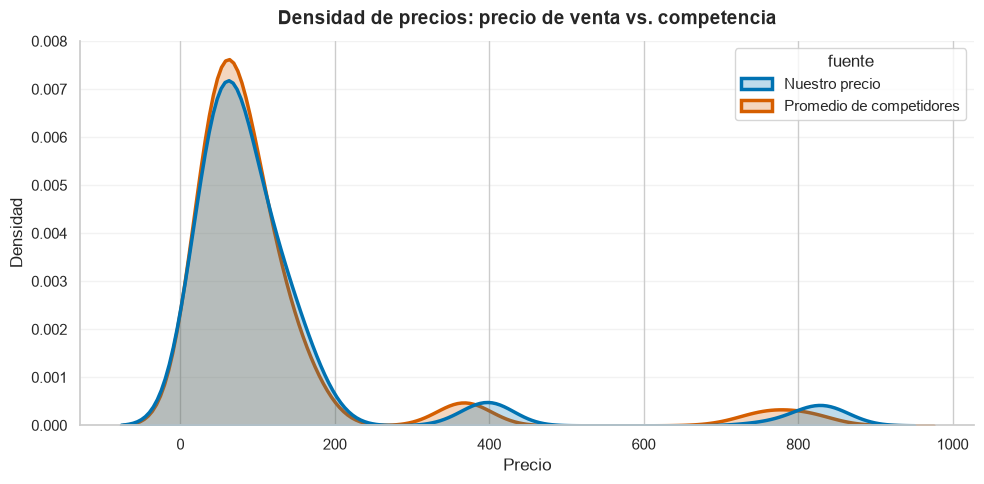

In [15]:
precios = pd.DataFrame({
    'Nuestro precio': df['precio_venta'],
    'Promedio de competidores': df[['Amazon', 'Decathlon', 'Deporvillage']].mean(axis=1),
}).melt(var_name='fuente', value_name='precio')

colores_precios = {'Nuestro precio': '#0072B2', 'Promedio de competidores': '#D55E00'}
fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(data=precios, x='precio', hue='fuente', common_norm=False,
            hue_order=list(colores_precios), palette=colores_precios,
            fill=True, alpha=0.25, linewidth=2.5, ax=ax)
ax.set_title('Densidad de precios: precio de venta vs. competencia', fontsize=14,
             fontweight='bold', pad=12)
ax.set(xlabel='Precio', ylabel='Densidad')
ax.grid(axis='y', alpha=0.25)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

## Creacion de variables temporales y de calendario

Se derivan atributos de fecha para el modelado. Los festivos corresponden al calendario nacional de Espana; no se incluyen festivos autonomicos o locales porque no se ha especificado una comunidad o municipio.

In [16]:
fechas_df = pd.to_datetime(df['fecha'])
anios_df = sorted(fechas_df.dt.year.dropna().unique().tolist())
calendario_festivos_es = holidays.country_holidays(
    'ES', years=[int(anio) for anio in anios_df]
)

df['anio'] = fechas_df.dt.year
df['mes'] = fechas_df.dt.month
df['dia_mes'] = fechas_df.dt.day
df['dia_semana'] = fechas_df.dt.dayofweek
df['nombre_dia_semana'] = fechas_df.dt.dayofweek.map(
    dict(enumerate(['Lunes', 'Martes', 'Miercoles', 'Jueves', 'Viernes', 'Sabado', 'Domingo']))
)
df['trimestre'] = fechas_df.dt.quarter
df['dia_del_anio'] = fechas_df.dt.dayofyear
df['semana_iso'] = fechas_df.dt.isocalendar().week.astype('int64')

df['es_fin_de_semana'] = df['dia_semana'].isin([5, 6])
df['es_inicio_mes'] = df['dia_mes'] <= 3
df['es_fin_mes'] = df['dia_mes'] > (fechas_df.dt.days_in_month - 3)
df['mes_sin'] = np.sin(2 * np.pi * (df['mes'] - 1) / 12)
df['mes_cos'] = np.cos(2 * np.pi * (df['mes'] - 1) / 12)
df['dia_semana_sin'] = np.sin(2 * np.pi * df['dia_semana'] / 7)
df['dia_semana_cos'] = np.cos(2 * np.pi * df['dia_semana'] / 7)

fechas_solo_dia = fechas_df.dt.date
df['es_festivo_es'] = fechas_solo_dia.isin(calendario_festivos_es)
df['nombre_festivo_es'] = fechas_solo_dia.map(calendario_festivos_es.get).fillna('No festivo')

fechas_black_friday = {}
for anio in anios_df:
    viernes_noviembre = pd.date_range(
        start=f'{int(anio)}-11-01', end=f'{int(anio)}-11-30', freq='W-FRI'
    )
    fechas_black_friday[int(anio)] = viernes_noviembre[-1]

fechas_cyber_monday = {
    anio: fecha_black_friday + pd.Timedelta(days=3)
    for anio, fecha_black_friday in fechas_black_friday.items()
}
fechas_normalizadas = fechas_df.dt.normalize()
df['es_black_friday'] = fechas_normalizadas.isin(fechas_black_friday.values())
df['es_cyber_monday'] = fechas_normalizadas.isin(fechas_cyber_monday.values())
fechas_campana_black_friday = [
    fecha + pd.Timedelta(days=dia)
    for fecha in fechas_black_friday.values()
    for dia in range(4)
]
df['es_campana_black_friday'] = fechas_normalizadas.isin(fechas_campana_black_friday)

variables_temporales = [
    'anio', 'mes', 'dia_mes', 'dia_semana', 'nombre_dia_semana', 'trimestre',
    'dia_del_anio', 'semana_iso', 'es_fin_de_semana', 'es_inicio_mes',
    'es_fin_mes', 'mes_sin', 'mes_cos', 'dia_semana_sin', 'dia_semana_cos',
    'es_festivo_es', 'nombre_festivo_es', 'es_black_friday',
    'es_cyber_monday', 'es_campana_black_friday',
]

print(f'Variables temporales creadas: {len(variables_temporales)}')
display(df[variables_temporales].head())

print('Festivos nacionales de Espana presentes en los datos:')
display(
    df.loc[df['es_festivo_es'], ['fecha', 'nombre_festivo_es']]
    .drop_duplicates().sort_values('fecha').reset_index(drop=True)
)

print('Fechas de Black Friday y Cyber Monday con cobertura en df:')
display(
    df.loc[df['es_black_friday'] | df['es_cyber_monday'],
           ['fecha', 'es_black_friday', 'es_cyber_monday']]
    .drop_duplicates().sort_values('fecha').reset_index(drop=True)
)
print('Fechas de Cyber Monday calculadas por ano:', {
    anio: fecha.date() for anio, fecha in fechas_cyber_monday.items()
})

Variables temporales creadas: 20


C:\Users\Vehiller\AppData\Local\Temp\ipykernel_12696\705660044.py:10: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['dia_semana'] = fechas_df.dt.dayofweek
C:\Users\Vehiller\AppData\Local\Temp\ipykernel_12696\705660044.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['nombre_dia_semana'] = fechas_df.dt.dayofweek.map(
C:\Users\Vehiller\AppData\Local\Temp\ipykernel_12696\705660044.py:15: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df['dia_del_anio'] = fechas_df.dt.dayofyear


,anio,mes,dia_mes,dia_semana,nombre_dia_semana,trimestre,dia_del_anio,semana_iso,es_fin_de_semana,es_inicio_mes,es_fin_mes,mes_sin,mes_cos,dia_semana_sin,dia_semana_cos,es_festivo_es,nombre_festivo_es,es_black_friday,es_cyber_monday,es_campana_black_friday
0,2021,10,25,0,Lunes,4,298,43,False,False,False,-1.0,-1.836970e-16,0.0,1.0,False,No festivo,False,False,False
1,2021,10,25,0,Lunes,4,298,43,False,False,False,-1.0,-1.836970e-16,0.0,1.0,False,No festivo,False,False,False
2,2021,10,25,0,Lunes,4,298,43,False,False,False,-1.0,-1.836970e-16,0.0,1.0,False,No festivo,False,False,False
3,2021,10,25,0,Lunes,4,298,43,False,False,False,-1.0,-1.836970e-16,0.0,1.0,False,No festivo,False,False,False
4,2021,10,25,0,Lunes,4,298,43,False,False,False,-1.0,-1.836970e-16,0.0,1.0,False,No festivo,False,False,False


Festivos nacionales de Espana presentes en los datos:


,fecha,nombre_festivo_es
0,2021-11-01,Todos los Santos
1,2022-11-01,Todos los Santos
2,2023-11-01,Todos los Santos
3,2024-11-01,Todos los Santos


Fechas de Black Friday y Cyber Monday con cobertura en df:


,fecha,es_black_friday,es_cyber_monday
0,2021-11-26,True,False
1,2021-11-29,False,True
2,2022-11-25,True,False
3,2022-11-28,False,True
4,2023-11-24,True,False
5,2023-11-27,False,True
6,2024-11-29,True,False


Fechas de Cyber Monday calculadas por ano: {2021: datetime.date(2021, 11, 29), 2022: datetime.date(2022, 11, 28), 2023: datetime.date(2023, 11, 27), 2024: datetime.date(2024, 12, 2)}


## Rezagos y media movil de unidades vendidas

Los rezagos y la media movil se calculan por producto y ano, en orden cronologico. La media movil usa los siete dias anteriores, excluyendo el dia actual para evitar fuga de informacion.

In [17]:
df.shape

(3552, 33)

In [18]:
if 'anio' not in df.columns:
    df['anio'] = pd.to_datetime(df['fecha']).dt.year

df = df.sort_values(['producto_id', 'anio', 'fecha']).copy()
grupo_unidades = df.groupby(
    ['producto_id', 'anio'], sort=False
)['unidades_vendidas']

columnas_lags = []
for periodo in range(1, 8):
    nombre_lag = f'unidades_lag_{periodo}'
    df[nombre_lag] = grupo_unidades.shift(periodo)
    columnas_lags.append(nombre_lag)

df['media_movil_7_dias'] = grupo_unidades.transform(
    lambda serie: serie.shift(1).rolling(window=7, min_periods=7).mean()
)
variables_historial = columnas_lags + ['media_movil_7_dias']

filas_antes = len(df)
filas_incompletas = df[variables_historial].isna().any(axis=1).sum()
df = df.dropna(subset=variables_historial).reset_index(drop=True)

print(f'Registros de entrada: {filas_antes}')
print(f'Registros eliminados por historial incompleto: {filas_incompletas}')
print(f'Registros disponibles en df: {len(df)}')
print('Registros disponibles por ano:')
print(df.groupby('anio').size())
print('Nulos restantes en las nuevas variables:',
      df[variables_historial].isna().sum().sum())
display(df[
    ['fecha', 'producto_id', 'anio', 'unidades_vendidas'] + variables_historial
].head(10))

Registros de entrada: 3552
Registros eliminados por historial incompleto: 672
Registros disponibles en df: 2880
Registros disponibles por ano:
anio
2021    720
2022    720
2023    720
2024    720
dtype: int64
Nulos restantes en las nuevas variables: 0


,fecha,producto_id,anio,unidades_vendidas,unidades_lag_1,unidades_lag_2,unidades_lag_3,unidades_lag_4,unidades_lag_5,unidades_lag_6,unidades_lag_7,media_movil_7_dias
0,2021-11-01,PROD_001,2021,7,9.0,12.0,12.0,7.0,8.0,8.0,6.0,8.857143
1,2021-11-02,PROD_001,2021,10,7.0,9.0,12.0,12.0,7.0,8.0,8.0,9.000000
2,2021-11-03,PROD_001,2021,11,10.0,7.0,9.0,12.0,12.0,7.0,8.0,9.285714
3,2021-11-04,PROD_001,2021,12,11.0,10.0,7.0,9.0,12.0,12.0,7.0,9.714286
4,2021-11-05,PROD_001,2021,10,12.0,11.0,10.0,7.0,9.0,12.0,12.0,10.428571
5,2021-11-06,PROD_001,2021,10,10.0,12.0,11.0,10.0,7.0,9.0,12.0,10.142857
6,2021-11-07,PROD_001,2021,10,10.0,10.0,12.0,11.0,10.0,7.0,9.0,9.857143
7,2021-11-08,PROD_001,2021,9,10.0,10.0,10.0,12.0,11.0,10.0,7.0,10.000000
8,2021-11-09,PROD_001,2021,11,9.0,10.0,10.0,10.0,12.0,11.0,10.0,10.285714
9,2021-11-10,PROD_001,2021,10,11.0,9.0,10.0,10.0,10.0,12.0,11.0,10.428571


In [19]:
df['descuento_porcentaje'] = (
    (df['precio_venta'] - df['precio_base']) / df['precio_base'] * 100
)

display(df[['fecha', 'producto_id', 'precio_base', 'precio_venta', 'descuento_porcentaje']].head())

,fecha,producto_id,precio_base,precio_venta,descuento_porcentaje
0,2021-11-01,PROD_001,115,115.07,0.060870
1,2021-11-02,PROD_001,115,116.10,0.956522
2,2021-11-03,PROD_001,115,114.58,-0.365217
3,2021-11-04,PROD_001,115,112.23,-2.408696
4,2021-11-05,PROD_001,115,113.81,-1.034783


In [20]:
# Asegurar la disponibilidad de los precios individuales de competencia.
competidores = ['Amazon', 'Decathlon', 'Deporvillage']

# Retirar sufijos que puedan haber quedado de una union anterior.
columnas_competencia_sufijadas = [
    columna
    for competidor in competidores
    for columna in (f'{competidor}_x', f'{competidor}_y')
    if columna in df.columns
]
df = df.drop(columns=columnas_competencia_sufijadas)

# Si falta alguna columna, recuperarlas desde competencia_df usando las claves.
if not all(competidor in df.columns for competidor in competidores):
    columnas_competencia_existentes = [
        competidor for competidor in competidores if competidor in df.columns
    ]
    df = df.drop(columns=columnas_competencia_existentes)
    precios_competencia = competencia_df[['fecha', 'producto_id'] + competidores]
    df = df.merge(
        precios_competencia,
        on=['fecha', 'producto_id'],
        how='left',
        validate='one_to_one',
    )

# Calcular el promedio de precios de competencia por registro.
df['precio_competencia'] = df[competidores].mean(axis=1)

# Calcular la relacion entre nuestro precio y el promedio de competencia.
df['ratio_precio'] = df['precio_venta'] / df['precio_competencia']

# Eliminar las columnas individuales cuando las variables agregadas esten listas.
df = df.drop(columns=['Amazon', 'Decathlon', 'Deporvillage'])

# Verificar las variables nuevas en las primeras filas del DataFrame.
display(df[['fecha', 'producto_id', 'precio_venta', 'precio_competencia', 'ratio_precio']].head())

,fecha,producto_id,precio_venta,precio_competencia,ratio_precio
0,2021-11-01,PROD_001,115.07,95.353333,1.206775
1,2021-11-02,PROD_001,116.10,96.153333,1.207446
2,2021-11-03,PROD_001,114.58,95.240000,1.203066
3,2021-11-04,PROD_001,112.23,96.590000,1.161922
4,2021-11-05,PROD_001,113.81,96.170000,1.183425


In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2880 entries, 0 to 2879
Data columns (total 41 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   fecha                    2880 non-null   datetime64[us]
 1   producto_id              2880 non-null   str           
 2   nombre                   2880 non-null   str           
 3   categoria                2880 non-null   str           
 4   subcategoria             2880 non-null   str           
 5   precio_base              2880 non-null   int64         
 6   es_estrella              2880 non-null   bool          
 7   unidades_vendidas        2880 non-null   int64         
 8   precio_venta             2880 non-null   float64       
 9   ingresos                 2880 non-null   float64       
 10  anio                     2880 non-null   int32         
 11  mes                      2880 non-null   int32         
 12  dia_mes                  2880 non-null   int3

In [22]:
# Crear copias de las variables categoricas para codificarlas sin alterar las originales.
variables_categoricas_h = ['nombre_h', 'categoria_h', 'subcategoria_h']
variables_originales = ['nombre', 'categoria', 'subcategoria']

for variable_h, variable_original in zip(variables_categoricas_h, variables_originales):
    df[variable_h] = df[variable_original].copy()

# Generar las columnas one-hot a partir de las copias con sufijo _h.
columnas_one_hot = pd.get_dummies(
    df[variables_categoricas_h],
    prefix=variables_categoricas_h,
    dtype=int,
)

# Reemplazar codificaciones anteriores para que la celda sea segura al reejecutarse.
prefijos_one_hot = tuple(f'{variable}_' for variable in variables_categoricas_h)
columnas_one_hot_existentes = [
    columna for columna in df.columns if columna.startswith(prefijos_one_hot)
]
df = df.drop(columns=columnas_one_hot_existentes)
df = pd.concat([df, columnas_one_hot], axis=1)

# Mostrar las copias originales y las columnas codificadas para verificar el resultado.
display(df[variables_categoricas_h + columnas_one_hot.columns.tolist()].head())

,nombre_h,categoria_h,subcategoria_h,nombre_h_Adidas Own The Run Jacket,nombre_h_Adidas Ultraboost 23,nombre_h_Asics Gel Nimbus 25,nombre_h_Bowflex SelectTech 552,nombre_h_Columbia Silver Ridge,nombre_h_Decathlon Bandas Elásticas Set,nombre_h_Domyos BM900,...,subcategoria_h_Esterilla Yoga,subcategoria_h_Mancuernas Ajustables,subcategoria_h_Mochila Trekking,subcategoria_h_Pesa Rusa,subcategoria_h_Pesas Casa,subcategoria_h_Rodillera Yoga,subcategoria_h_Ropa Montaña,subcategoria_h_Ropa Running,subcategoria_h_Zapatillas Running,subcategoria_h_Zapatillas Trail
0,Nike Air Zoom Pegasus 40,Running,Zapatillas Running,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,Nike Air Zoom Pegasus 40,Running,Zapatillas Running,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,Nike Air Zoom Pegasus 40,Running,Zapatillas Running,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
3,Nike Air Zoom Pegasus 40,Running,Zapatillas Running,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
4,Nike Air Zoom Pegasus 40,Running,Zapatillas Running,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0


In [23]:
# Guardar el DataFrame final en la carpeta de datos procesados.
from pathlib import Path

ruta_salida = Path('../data/processed/df.csv')
ruta_salida.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(ruta_salida, index=False, encoding='utf-8')
print(f'DataFrame guardado en: {ruta_salida.resolve()}')

DataFrame guardado en: C:\Users\Vehiller\Documents\GitHub\ds4b-experienc-ia-en-data-science\data\processed\df.csv


In [24]:
# Dividir el conjunto por año para entrenamiento y validación temporal.
fechas_df = pd.to_datetime(df['fecha'])
anos_df = fechas_df.dt.year

train_df = df.loc[anos_df.between(2021, 2023)].copy()
validation_df = df.loc[anos_df == 2024].copy()

print(f'Registros de entrenamiento (2021-2023): {len(train_df)}')
print(f'Registros de validación (2024): {len(validation_df)}')

Registros de entrenamiento (2021-2023): 2160
Registros de validación (2024): 720


In [25]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)

target = 'unidades_vendidas'
columnas_excluidas = [target, 'fecha', 'ingresos']
variables_predictoras = train_df.drop(columns=columnas_excluidas).select_dtypes(
    include=['number', 'bool']
).columns.tolist()

X_train = train_df[variables_predictoras]
y_train = train_df[target]
X_validation = validation_df[variables_predictoras]
y_validation = validation_df[target]

modelo_hgb = HistGradientBoostingRegressor(
    learning_rate=0.03,
    max_iter=500,
    max_depth=5,
    max_leaf_nodes=15,
    min_samples_leaf=20,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42,
)
modelo_hgb.fit(X_train, y_train)
predicciones_hgb = modelo_hgb.predict(X_validation)

# El baseline predice en validación la media observada en entrenamiento.
predicciones_naive = np.full(len(y_validation), y_train.mean())

metricas = []
for nombre_modelo, predicciones in [
    ('HistGradientBoostingRegressor', predicciones_hgb),
    ('Baseline naive (media)', predicciones_naive),
]:
    metricas.append({
        'modelo': nombre_modelo,
        'MAE': mean_absolute_error(y_validation, predicciones),
        'RMSE': np.sqrt(mean_squared_error(y_validation, predicciones)),
        'MAPE (%)': 100 * mean_absolute_percentage_error(y_validation, predicciones),
        'R2': r2_score(y_validation, predicciones),
    })

metricas_df = pd.DataFrame(metricas).set_index('modelo')
print(f'Número de predictoras: {len(variables_predictoras)}')
display(metricas_df.round(3))

Número de predictoras: 76


,MAE,RMSE,MAPE (%),R2
modelo,,,,
HistGradientBoostingRegressor,1.062,2.274,18.864,0.885
Baseline naive (media),3.669,6.692,93.022,-0.000


Productos estrella con datos en noviembre de 2024: 7


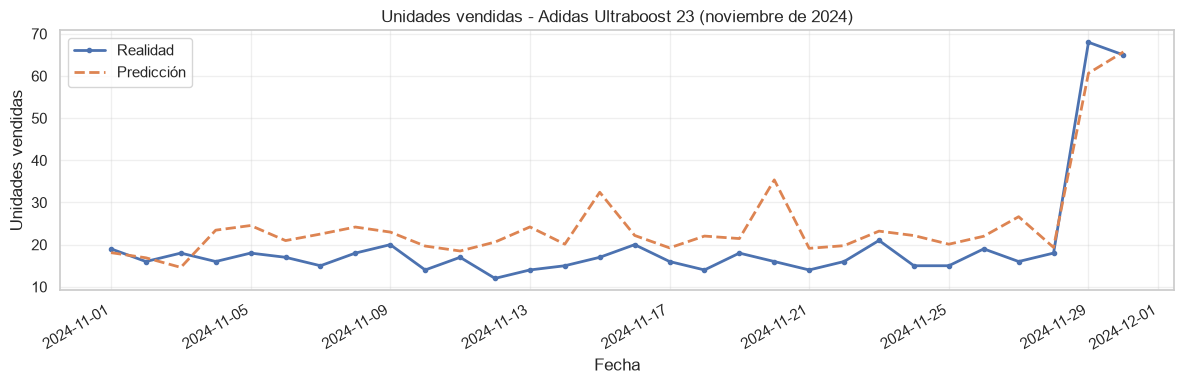

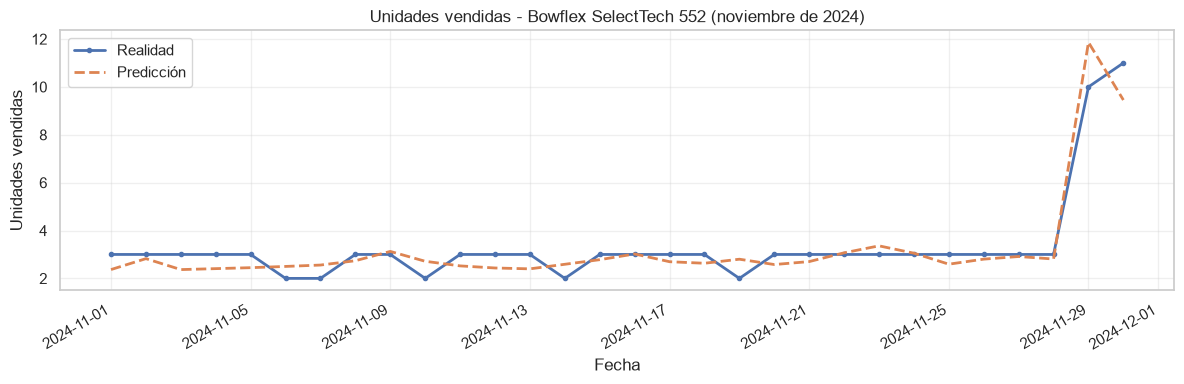

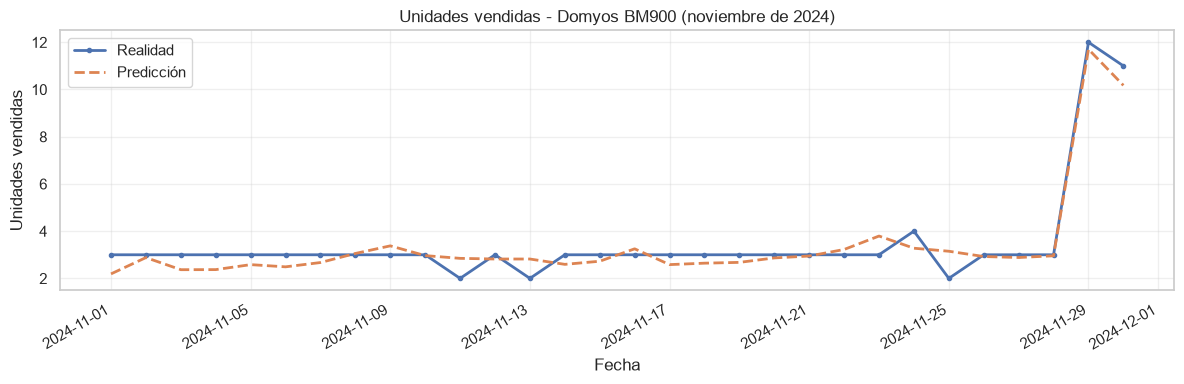

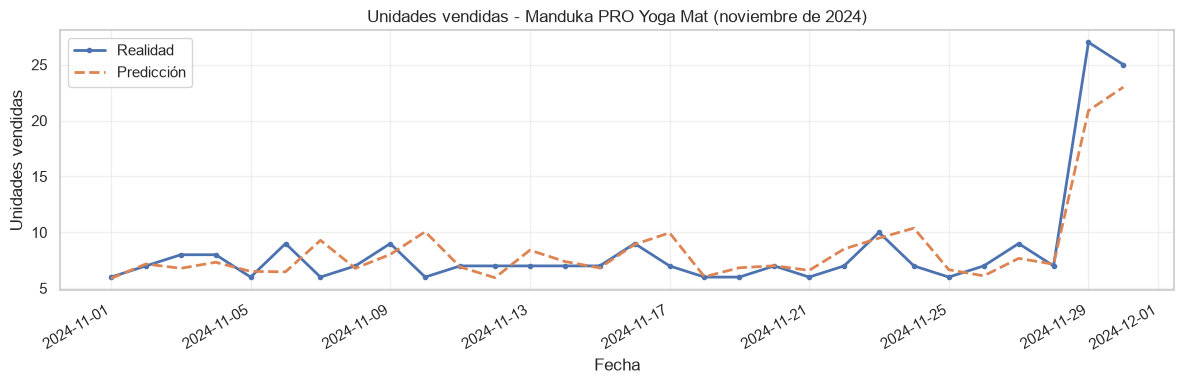

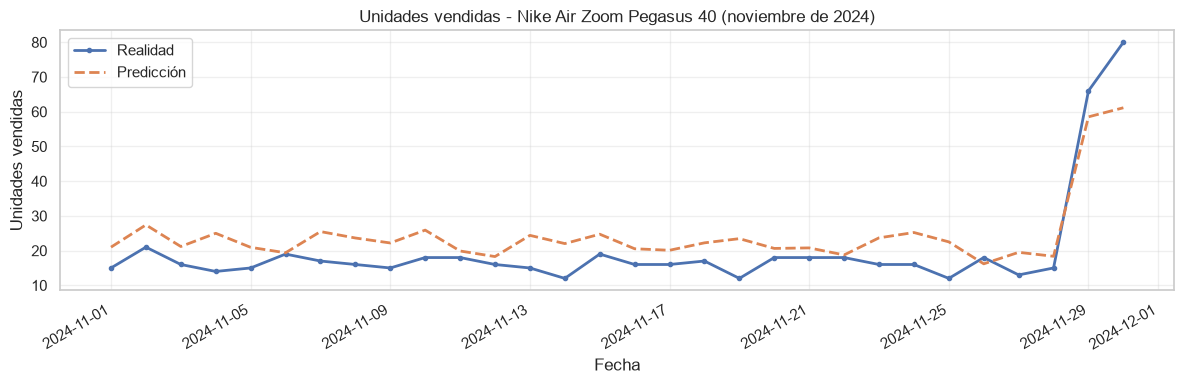

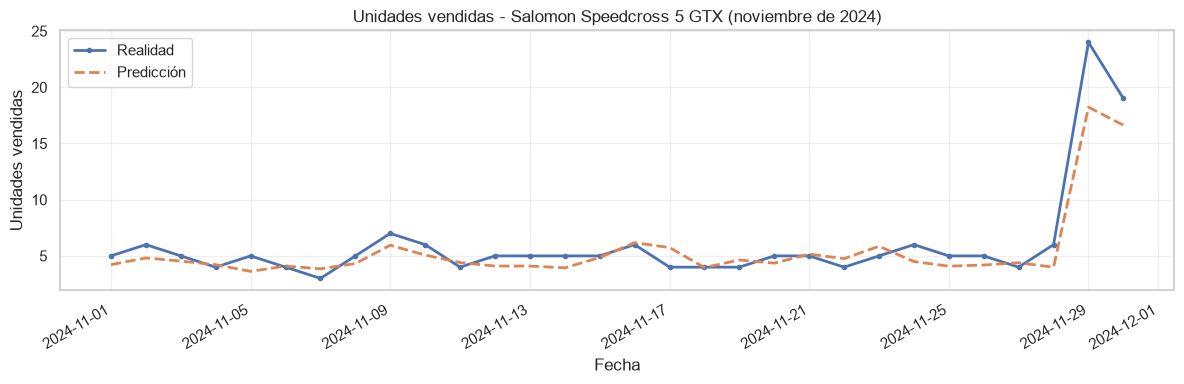

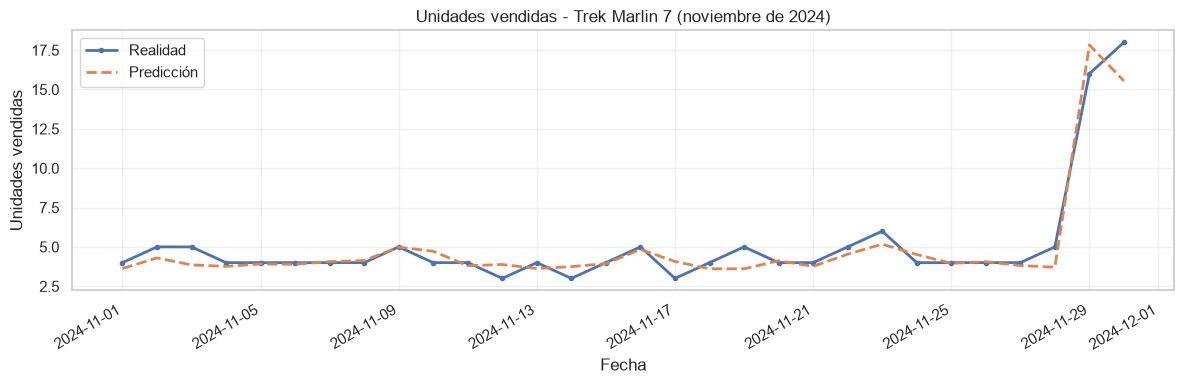

In [26]:
# Predecir noviembre de 2024 para los productos estrella y comparar con la realidad.
fechas_validacion = pd.to_datetime(validation_df['fecha'])
noviembre_2024 = validation_df.loc[
    fechas_validacion.between('2024-11-01', '2024-11-30')
].copy()
noviembre_2024['prediccion_unidades'] = modelo_hgb.predict(
    noviembre_2024[variables_predictoras]
)

productos_estrella_noviembre = noviembre_2024.loc[
    noviembre_2024['es_estrella'], ['producto_id', 'nombre']
].drop_duplicates().sort_values('nombre')
print(f'Productos estrella con datos en noviembre de 2024: {len(productos_estrella_noviembre)}')

for producto in productos_estrella_noviembre.itertuples(index=False):
    datos_producto = noviembre_2024.loc[
        noviembre_2024['producto_id'] == producto.producto_id
    ].sort_values('fecha')

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(
        datos_producto['fecha'],
        datos_producto['unidades_vendidas'],
        label='Realidad',
        linewidth=2,
        marker='o',
        markersize=3,
    )
    ax.plot(
        datos_producto['fecha'],
        datos_producto['prediccion_unidades'],
        label='Predicción',
        linewidth=2,
        linestyle='--',
    )
    ax.set_title(f'Unidades vendidas - {producto.nombre} (noviembre de 2024)')
    ax.set_xlabel('Fecha')
    ax.set_ylabel('Unidades vendidas')
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

In [27]:
# Calcular el MAE de noviembre de 2024 para cada producto estrella.
mae_productos_estrella = (
    noviembre_2024.loc[noviembre_2024['es_estrella']]
    .assign(
        error_absoluto=lambda datos: (
            datos['unidades_vendidas'] - datos['prediccion_unidades']
        ).abs()
    )
    .groupby(['producto_id', 'nombre'], as_index=False)['error_absoluto']
    .mean()
    .rename(columns={'error_absoluto': 'MAE'})
    .sort_values('MAE')
)
display(mae_productos_estrella.round({'MAE': 3}))

,producto_id,nombre,MAE
3,PROD_010,Domyos BM900,0.407
2,PROD_009,Bowflex SelectTech 552,0.473
5,PROD_016,Trek Marlin 7,0.564
4,PROD_015,Salomon Speedcross 5 GTX,0.994
6,PROD_021,Manduka PRO Yoga Mat,1.265
1,PROD_002,Adidas Ultraboost 23,5.632
0,PROD_001,Nike Air Zoom Pegasus 40,6.410


,periodo,registros,MAE,RMSE,MAPE (%)
0,Días 1-10,70,2.074,3.420,20.559
1,Días 11-20,70,2.312,4.429,23.312
2,Días 21-30,70,2.362,4.072,17.658


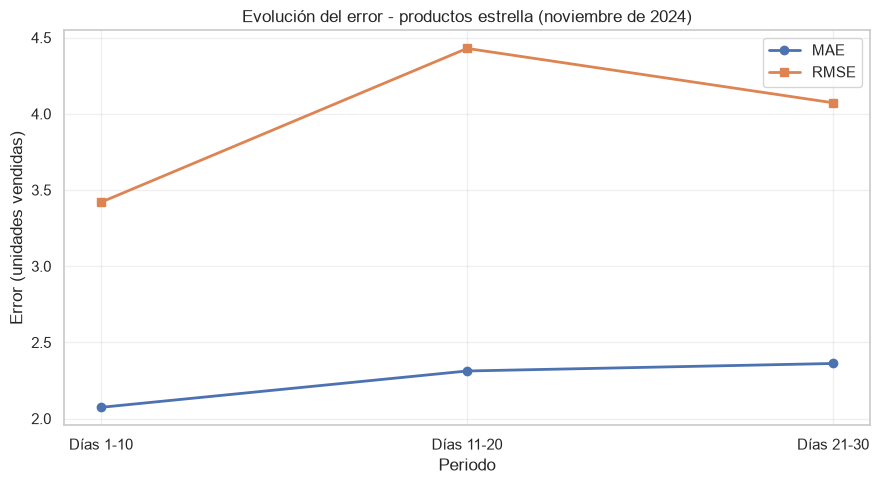

In [28]:
# Evaluar la evolución del error en tres periodos de diez días.
datos_periodos = noviembre_2024.loc[noviembre_2024['es_estrella']].copy()
datos_periodos['periodo'] = pd.cut(
    pd.to_datetime(datos_periodos['fecha']).dt.day,
    bins=[0, 10, 20, 30],
    labels=['Días 1-10', 'Días 11-20', 'Días 21-30'],
)

metricas_por_periodo = []
for periodo, grupo in datos_periodos.groupby('periodo', observed=True, sort=True):
    metricas_por_periodo.append({
        'periodo': str(periodo),
        'registros': len(grupo),
        'MAE': mean_absolute_error(
            grupo['unidades_vendidas'], grupo['prediccion_unidades']
        ),
        'RMSE': np.sqrt(mean_squared_error(
            grupo['unidades_vendidas'], grupo['prediccion_unidades']
        )),
        'MAPE (%)': 100 * mean_absolute_percentage_error(
            grupo['unidades_vendidas'], grupo['prediccion_unidades']
        ),
    })

metricas_periodo_df = pd.DataFrame(metricas_por_periodo)
display(metricas_periodo_df.round(3))

# MAE y RMSE comparten la unidad de la target y se comparan en el mismo eje.
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(
    metricas_periodo_df['periodo'], metricas_periodo_df['MAE'],
    marker='o', linewidth=2, label='MAE',
)
ax.plot(
    metricas_periodo_df['periodo'], metricas_periodo_df['RMSE'],
    marker='s', linewidth=2, label='RMSE',
)
ax.set_title('Evolución del error - productos estrella (noviembre de 2024)')
ax.set_xlabel('Periodo')
ax.set_ylabel('Error (unidades vendidas)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

,periodo,Días 1-10,Días 11-20,Días 21-30
producto_id,nombre,,,
PROD_001,Nike Air Zoom Pegasus 40,6.610,5.725,6.895
PROD_002,Adidas Ultraboost 23,4.546,7.712,4.638
PROD_009,Bowflex SelectTech 552,0.474,0.437,0.507
PROD_010,Domyos BM900,0.391,0.401,0.429
PROD_015,Salomon Speedcross 5 GTX,0.763,0.665,1.554
PROD_016,Trek Marlin 7,0.358,0.540,0.792
PROD_021,Manduka PRO Yoga Mat,1.373,0.705,1.715


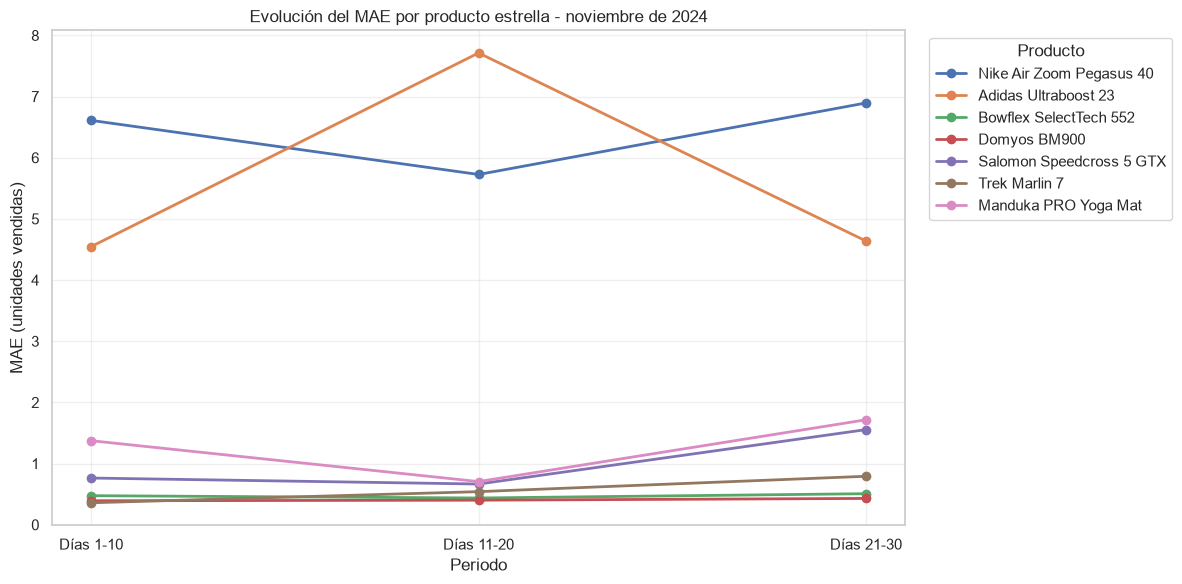

In [29]:
# Comparar el MAE de cada producto estrella a lo largo de los tres periodos.
datos_mae_producto = datos_periodos.assign(
    error_absoluto=lambda datos: (
        datos['unidades_vendidas'] - datos['prediccion_unidades']
    ).abs()
)
orden_periodos = ['Días 1-10', 'Días 11-20', 'Días 21-30']
mae_por_producto_periodo = (
    datos_mae_producto
    .groupby(['producto_id', 'nombre', 'periodo'], observed=True)['error_absoluto']
    .mean()
    .unstack('periodo')
    .reindex(columns=orden_periodos)
)
display(mae_por_producto_periodo.round(3))

fig, ax = plt.subplots(figsize=(12, 6))
for (producto_id, nombre), errores in mae_por_producto_periodo.iterrows():
    ax.plot(
        orden_periodos,
        errores,
        marker='o',
        linewidth=2,
        label=nombre,
    )
ax.set_title('Evolución del MAE por producto estrella - noviembre de 2024')
ax.set_xlabel('Periodo')
ax.set_ylabel('MAE (unidades vendidas)')
ax.legend(title='Producto', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

Productos evaluados: 24
MAE de Black Friday 2024: 2.29


,producto_id,nombre,realidad,prediccion_unidades
118,PROD_001,Nike Air Zoom Pegasus 40,66,58.526
238,PROD_002,Adidas Ultraboost 23,68,60.661
358,PROD_003,Asics Gel Nimbus 25,18,15.862
478,PROD_004,New Balance Fresh Foam X 1080v12,14,14.550
598,PROD_005,Nike Dri-FIT Miler,14,14.628
718,PROD_006,Adidas Own The Run Jacket,12,15.196
838,PROD_007,Puma Velocity Nitro 2,13,10.974
958,PROD_008,Reebok Floatride Energy 5,12,12.577
1078,PROD_009,Bowflex SelectTech 552,10,11.865
1198,PROD_010,Domyos BM900,12,11.705


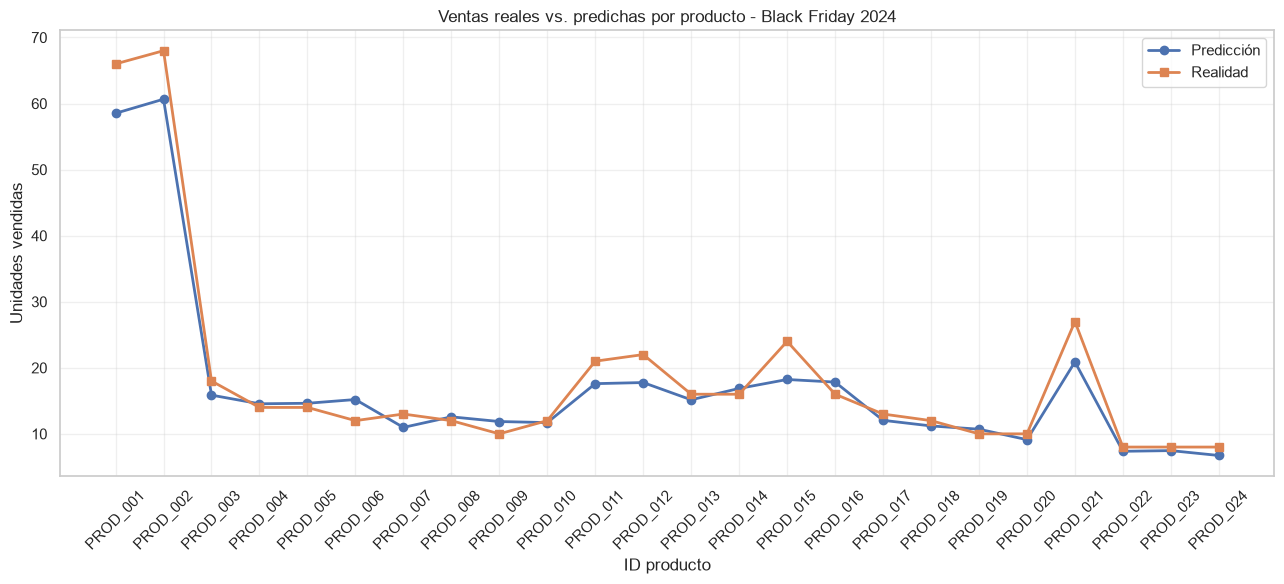

In [30]:
# Comparar las ventas reales y predichas para todos los productos en Black Friday 2024.
fecha_black_friday_2024 = pd.Timestamp('2024-11-29')
datos_black_friday = validation_df.loc[
    pd.to_datetime(validation_df['fecha']).dt.normalize().eq(fecha_black_friday_2024)
].copy()
datos_black_friday['prediccion_unidades'] = modelo_hgb.predict(
    datos_black_friday[variables_predictoras]
)
datos_black_friday = datos_black_friday.sort_values('producto_id')

comparacion_black_friday = datos_black_friday[
    ['producto_id', 'nombre', 'unidades_vendidas', 'prediccion_unidades']
].rename(columns={'unidades_vendidas': 'realidad'})
print(f'Productos evaluados: {len(comparacion_black_friday)}')
print(
    'MAE de Black Friday 2024:',
    round(mean_absolute_error(
        comparacion_black_friday['realidad'],
        comparacion_black_friday['prediccion_unidades'],
    ), 3),
)
display(comparacion_black_friday.round({'realidad': 3, 'prediccion_unidades': 3}))

fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(
    comparacion_black_friday['producto_id'],
    comparacion_black_friday['prediccion_unidades'],
    marker='o',
    linewidth=2,
    label='Predicción',
)
ax.plot(
    comparacion_black_friday['producto_id'],
    comparacion_black_friday['realidad'],
    marker='s',
    linewidth=2,
    label='Realidad',
)
ax.set_title('Ventas reales vs. predichas por producto - Black Friday 2024')
ax.set_xlabel('ID producto')
ax.set_ylabel('Unidades vendidas')
ax.tick_params(axis='x', rotation=45)
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

In [31]:
# Reentrenar el modelo final con todos los registros disponibles (2021-2024).
X_final = df[variables_predictoras]
y_final = df[target]

modelo_final = HistGradientBoostingRegressor(
    learning_rate=0.03,
    max_iter=500,
    max_depth=5,
    max_leaf_nodes=15,
    min_samples_leaf=20,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42,
)
modelo_final.fit(X_final, y_final)

print(f'Registros de entrenamiento: {len(X_final)}')
print(f'Periodo de entrenamiento: {df["fecha"].min().date()} a {df["fecha"].max().date()}')
print(f'Número de predictoras: {len(variables_predictoras)}')

Registros de entrenamiento: 2880
Periodo de entrenamiento: 2021-11-01 a 2024-11-30
Número de predictoras: 76


,variable,importancia_MAE,desviacion_std
27,unidades_lag_7,1.026,0.022
20,es_campana_black_friday,0.827,0.024
21,unidades_lag_1,0.665,0.006
28,media_movil_7_dias,0.614,0.016
29,descuento_porcentaje,0.432,0.026
31,ratio_precio,0.202,0.022
26,unidades_lag_6,0.134,0.009
15,dia_semana_sin,0.055,0.003
5,dia_mes,0.042,0.002
22,unidades_lag_2,0.041,0.001


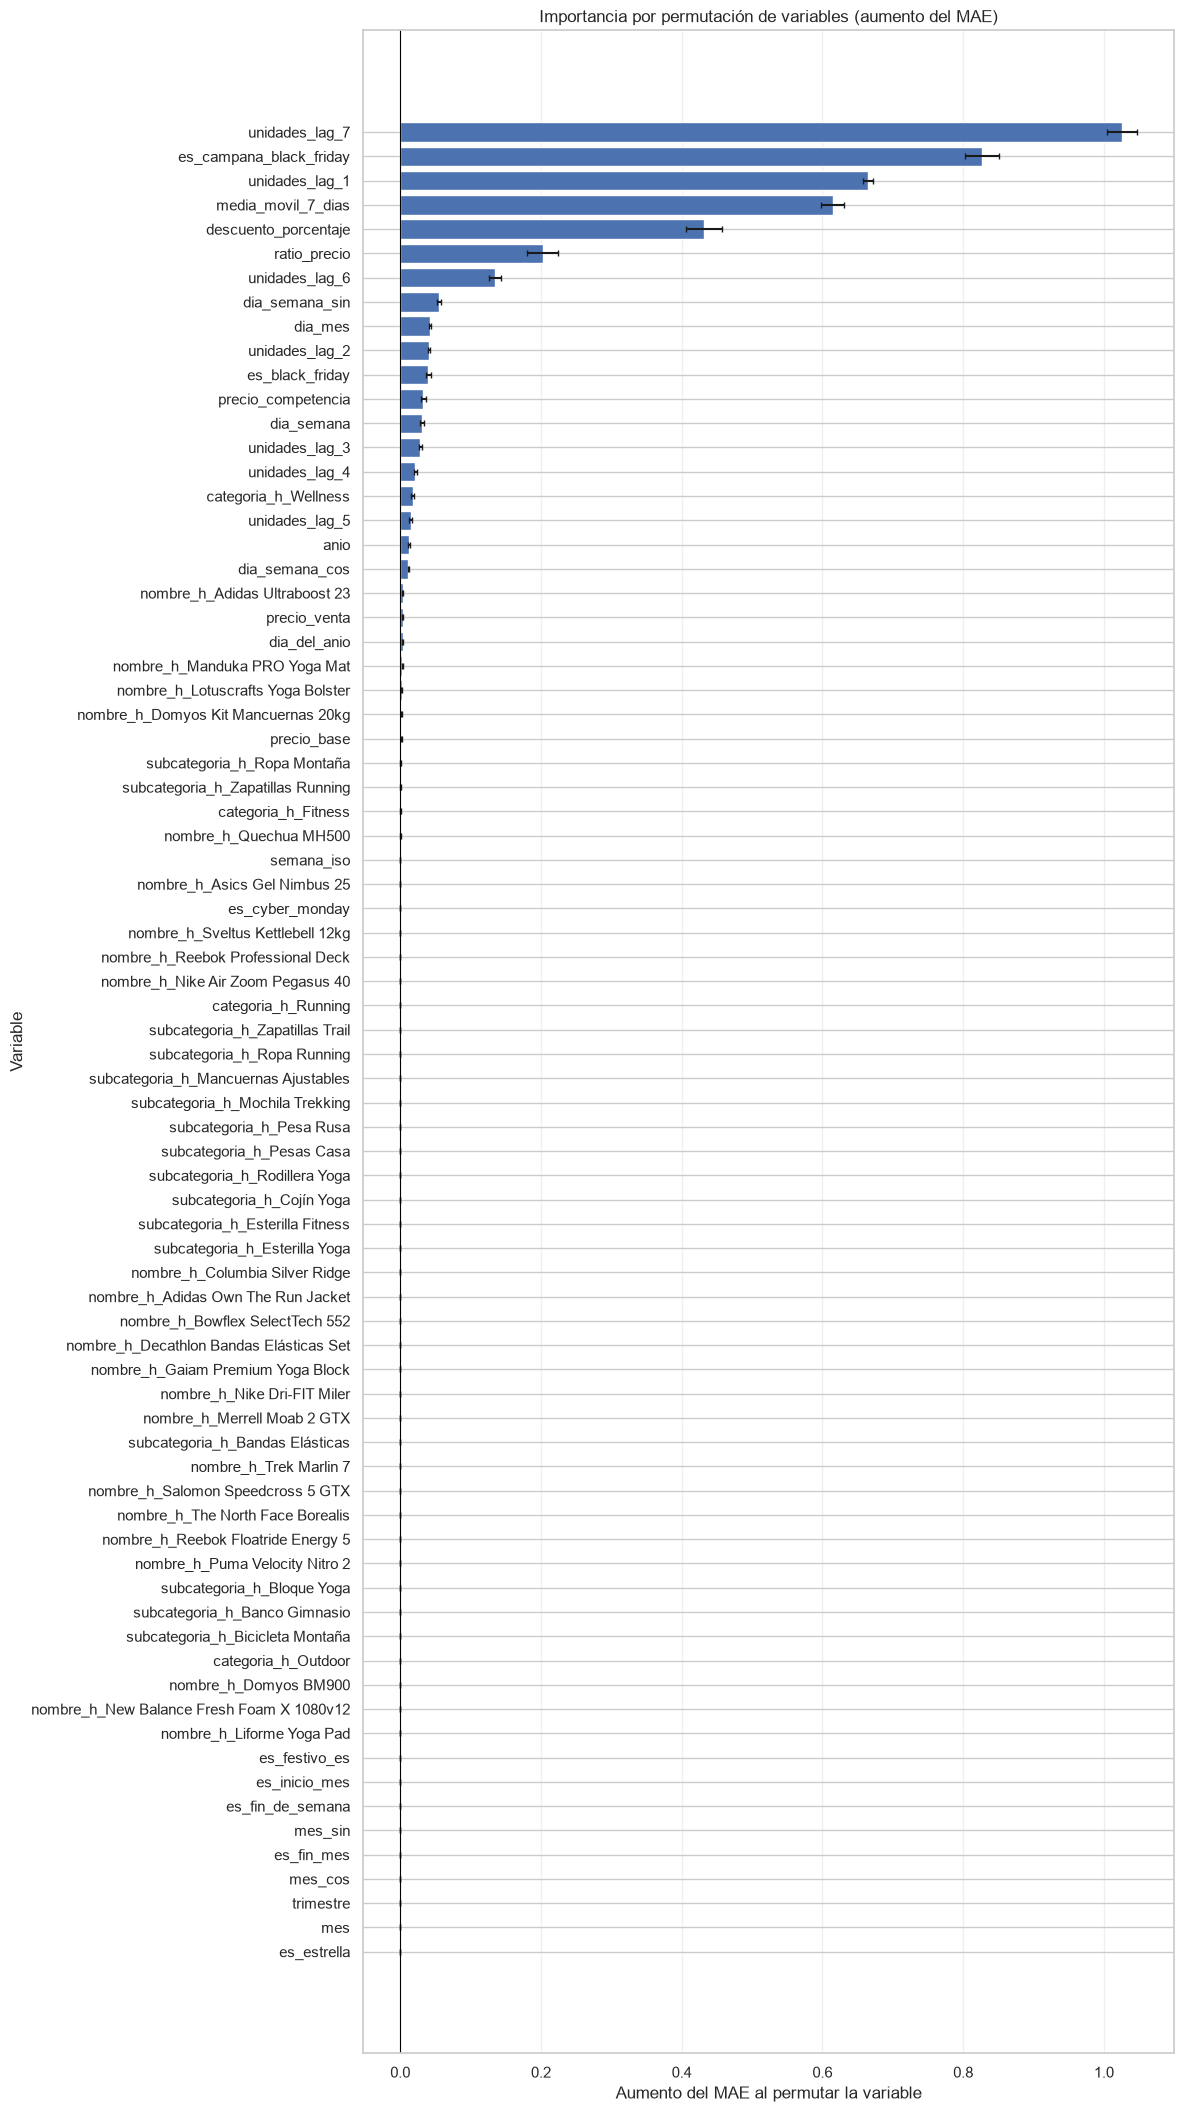

Modelo final guardado en: C:\Users\Vehiller\Documents\GitHub\ds4b-experienc-ia-en-data-science\models\modelo_final.joblib


In [32]:
from pathlib import Path
import joblib
from sklearn.inspection import permutation_importance

# Medir el aumento del MAE al permutar cada predictor en los datos históricos.
importancia_permutacion = permutation_importance(
    modelo_final,
    X_final,
    y_final,
    scoring='neg_mean_absolute_error',
    n_repeats=10,
    random_state=42,
)
importancias_df = pd.DataFrame({
    'variable': variables_predictoras,
    'importancia_MAE': importancia_permutacion.importances_mean,
    'desviacion_std': importancia_permutacion.importances_std,
}).sort_values('importancia_MAE', ascending=False)
display(importancias_df.head(20).round(3))

orden_importancias = np.argsort(importancia_permutacion.importances_mean)
fig, ax = plt.subplots(
    figsize=(12, max(8, len(variables_predictoras) * 0.28))
)
ax.barh(
    np.array(variables_predictoras)[orden_importancias],
    importancia_permutacion.importances_mean[orden_importancias],
    xerr=importancia_permutacion.importances_std[orden_importancias],
    capsize=2,
)
ax.set_title('Importancia por permutación de variables (aumento del MAE)')
ax.set_xlabel('Aumento del MAE al permutar la variable')
ax.set_ylabel('Variable')
ax.axvline(0, color='black', linewidth=0.8)
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
plt.show()

ruta_modelo_final = Path('../models/modelo_final.joblib')
ruta_modelo_final.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(modelo_final, ruta_modelo_final)
print(f'Modelo final guardado en: {ruta_modelo_final.resolve()}')